In [ ]:
!pip install -q xgboost shap imbalanced-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving diabetes+130-us+hospitals+for+years+1999-2008.zip to diabetes+130-us+hospitals+for+years+1999-2008.zip


In [ ]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

extract_path = "/content/diabetes_dataset"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files_list in os.walk(extract_path):
    for file in files_list:
        print(os.path.join(root, file))

Dataset extracted successfully!
/content/diabetes_dataset/diabetic_data.csv
/content/diabetes_dataset/IDS_mapping.csv


In [ ]:
data_path = "/content/diabetes_dataset/diabetic_data.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

Dataset shape: (101766, 50)


In [ ]:
print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

First 5 rows:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-

In [ ]:
print(df["readmitted"].value_counts())

print("\nPercentages:")
print(
    df["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Percentages:
readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


In [ ]:
# 1 = readmitted within 30 days
# 0 = not readmitted within 30 days

df["readmitted_30"] = (
    df["readmitted"] == "<30"
).astype(int)

print("30-Day Readmission Distribution:")
print(df["readmitted_30"].value_counts())

print("\nPercentage:")
print(
    df["readmitted_30"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

30-Day Readmission Distribution:
readmitted_30
0    90409
1    11357
Name: count, dtype: int64

Percentage:
readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64


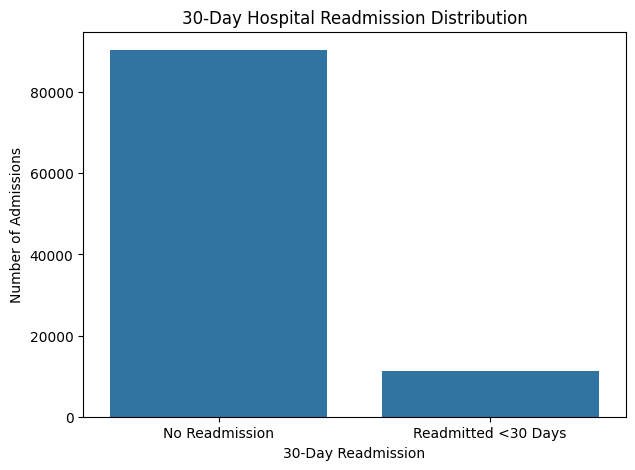

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="readmitted_30"
)

plt.title("30-Day Hospital Readmission Distribution")
plt.xlabel("30-Day Readmission")
plt.ylabel("Number of Admissions")
plt.xticks(
    [0, 1],
    ["No Readmission", "Readmitted <30 Days"]
)

plt.show()

In [ ]:
df = df.drop(
    columns=[
        "encounter_id",
        "patient_nbr",
        "readmitted"
    ]
)

print("New shape:", df.shape)

New shape: (101766, 48)


In [ ]:
df = df.replace("?", np.nan)

print(
    "Total missing values:",
    df.isnull().sum().sum()
)

Total missing values: 374017


In [ ]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(
    missing[
        missing["Missing Count"] > 0
    ].sort_values(
        "Missing Percentage",
        ascending=False
    )
)

,Missing Count,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [ ]:
columns_to_drop = [
    "weight",
    "max_glu_serum",
    "medical_specialty",
    "payer_code"
]

df = df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Removed:")
print(columns_to_drop)

print("\nNew shape:", df.shape)

Removed:
['weight', 'max_glu_serum', 'medical_specialty', 'payer_code']

New shape: (101766, 44)


In [ ]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    df[col] = df[col].fillna("Unknown")

print("Categorical missing values handled.")

Categorical missing values handled.


In [ ]:
numerical_columns = df.select_dtypes(
    exclude="object"
).columns

for col in numerical_columns:
    df[col] = df[col].fillna(
        df[col].median()
    )

print("Numerical missing values handled.")

print(
    "Remaining missing values:",
    df.isnull().sum().sum()
)

Numerical missing values handled.
Remaining missing values: 0


In [ ]:
# Previous healthcare utilization
df["total_previous_visits"] = (
    df["number_outpatient"]
    + df["number_emergency"]
    + df["number_inpatient"]
)

# Weighted utilization score
df["healthcare_utilization_score"] = (
    df["number_outpatient"]
    + 2 * df["number_emergency"]
    + 3 * df["number_inpatient"]
)

# Medication burden
df["medication_burden"] = (
    df["num_medications"]
)

# Diagnostic burden
df["diagnosis_burden"] = (
    df["number_diagnoses"]
)

# Procedure burden
df["procedure_burden"] = (
    df["num_procedures"]
    + df["num_lab_procedures"]
)

print("Healthcare features created.")

Healthcare features created.


In [ ]:
age_mapping = {
    "[0-10)": 5,
    "[10-20)": 15,
    "[20-30)": 25,
    "[30-40)": 35,
    "[40-50)": 45,
    "[50-60)": 55,
    "[60-70)": 65,
    "[70-80)": 75,
    "[80-90)": 85,
    "[90-100)": 95
}

df["age_numeric"] = df["age"].map(
    age_mapping
)

print(
    df[
        ["age", "age_numeric"]
    ].head()
)

       age  age_numeric
0   [0-10)            5
1  [10-20)           15
2  [20-30)           25
3  [30-40)           35
4  [40-50)           45


In [ ]:
df["medication_change"] = (
    df["change"]
    .map({
        "Ch": 1,
        "No": 0
    })
)

df["diabetes_medication"] = (
    df["diabetesMed"]
    .map({
        "Yes": 1,
        "No": 0
    })
)

print(
    df[
        [
            "change",
            "medication_change",
            "diabetesMed",
            "diabetes_medication"
        ]
    ].head()
)

  change  medication_change diabetesMed  diabetes_medication
0     No                  0          No                    0
1     Ch                  1         Yes                    1
2     No                  0         Yes                    1
3     Ch                  1         Yes                    1
4     Ch                  1         Yes                    1


In [ ]:
def diagnosis_category(code):

    if pd.isna(code):
        return "Unknown"

    code = str(code)

    try:
        value = float(code)
    except:
        return "Other"

    if 390 <= value <= 459:
        return "Circulatory"

    elif 460 <= value <= 519:
        return "Respiratory"

    elif 520 <= value <= 579:
        return "Digestive"

    elif 580 <= value <= 629:
        return "Genitourinary"

    elif 250 <= value < 251:
        return "Diabetes"

    elif 140 <= value <= 239:
        return "Neoplasms"

    elif 710 <= value <= 739:
        return "Musculoskeletal"

    elif 800 <= value <= 999:
        return "Injury"

    elif 1 <= value <= 139:
        return "Infectious"

    else:
        return "Other"

In [ ]:
df["diag_1_category"] = df["diag_1"].apply(
    diagnosis_category
)

df["diag_2_category"] = df["diag_2"].apply(
    diagnosis_category
)

df["diag_3_category"] = df["diag_3"].apply(
    diagnosis_category
)

print("Diagnosis grouping completed.")

display(
    df[
        [
            "diag_1",
            "diag_1_category",
            "diag_2",
            "diag_2_category"
        ]
    ].head()
)

Diagnosis grouping completed.


,diag_1,diag_1_category,diag_2,diag_2_category
0,250.83,Diabetes,Unknown,Other
1,276,Other,250.01,Diabetes
2,648,Other,250,Diabetes
3,8,Infectious,250.43,Diabetes
4,197,Neoplasms,157,Neoplasms


In [ ]:
df = df.drop(
    columns=[
        "diag_1",
        "diag_2",
        "diag_3"
    ]
)

print("Original diagnosis codes removed.")
print("Current shape:", df.shape)

Original diagnosis codes removed.
Current shape: (101766, 52)


In [ ]:
df = df.drop(
    columns=[
        "change",
        "diabetesMed"
    ],
    errors="ignore"
)

print("Redundant categorical columns removed.")
print("Current shape:", df.shape)

Redundant categorical columns removed.
Current shape: (101766, 50)


In [ ]:
print("Current dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print(
    "\nMissing values:",
    df.isnull().sum().sum()
)

Current dataset shape: (101766, 50)

Columns:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'readmitted_30', 'total_previous_visits', 'healthcare_utilization_score', 'medication_burden', 'diagnosis_burden', 'procedure_burden', 'age_numeric', 'medication_change', 'diabetes_medication', 'diag_1_category', 'diag_2_category', 'diag_3_category']

Missing values: 0


In [ ]:
X = df.drop(
    columns=["readmitted_30"]
)

y = df["readmitted_30"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (101766, 49)
y shape: (101766,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training: (81412, 49)
Testing: (20354, 49)

Training target:
readmitted_30
0    72326
1     9086
Name: count, dtype: int64

Testing target:
readmitted_30
0    18083
1     2271
Name: count, dtype: int64


In [ ]:
categorical_columns = X_train.select_dtypes(
    include="object"
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    exclude="object"
).columns.tolist()

print(
    "Categorical features:",
    len(categorical_columns)
)

print(
    "Numerical features:",
    len(numerical_columns)
)

Categorical features: 30
Numerical features: 19


In [ ]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

X_train_cat = encoder.fit_transform(
    X_train[categorical_columns]
)

X_test_cat = encoder.transform(
    X_test[categorical_columns]
)

print(
    "Encoded training shape:",
    X_train_cat.shape
)

print(
    "Encoded testing shape:",
    X_test_cat.shape
)

Encoded training shape: (81412, 122)
Encoded testing shape: (20354, 122)


In [ ]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(
    X_train[numerical_columns]
)

X_test_num = scaler.transform(
    X_test[numerical_columns]
)

print("Numerical scaling completed.")

Numerical scaling completed.


In [ ]:
from scipy.sparse import csr_matrix, hstack

X_train_num_sparse = csr_matrix(
    X_train_num
)

X_test_num_sparse = csr_matrix(
    X_test_num
)

X_train_processed = hstack([
    X_train_num_sparse,
    X_train_cat
]).tocsr()

X_test_processed = hstack([
    X_test_num_sparse,
    X_test_cat
]).tocsr()

print(
    "Final training shape:",
    X_train_processed.shape
)

print(
    "Final testing shape:",
    X_test_processed.shape
)

Final training shape: (81412, 141)
Final testing shape: (20354, 141)


In [ ]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTraining percentages:")
print(
    y_train
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Training class distribution:
readmitted_30
0    72326
1     9086
Name: count, dtype: int64

Training percentages:
readmitted_30
0    88.84
1    11.16
Name: proportion, dtype: float64


In [ ]:
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression trained!")

Logistic Regression trained!


In [ ]:
decision_tree = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=20,
    class_weight="balanced",
    random_state=42
)

decision_tree.fit(
    X_train_processed,
    y_train
)

print("Decision Tree trained!")

Decision Tree trained!


In [ ]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(
    X_train_processed,
    y_train
)

print("Random Forest trained!")

Random Forest trained!


In [ ]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = (
    negative_count / positive_count
)

print(
    "Scale positive weight:",
    round(scale_pos_weight, 2)
)

Scale positive weight: 7.96


In [ ]:
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=2
)

xgb_model.fit(
    X_train_processed,
    y_train
)

print("XGBoost trained!")

XGBoost trained!


In [ ]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "XGBoost": xgb_model
}

predictions = {}
probabilities = {}

for name, model in models.items():

    predictions[name] = model.predict(
        X_test_processed
    )

    probabilities[name] = model.predict_proba(
        X_test_processed
    )[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [ ]:
def evaluate_model(
    y_true,
    y_pred,
    y_prob
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    return {
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "Specificity": tn / (tn + fp),

        "F1-Score": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true,
            y_prob
        ),

        "PR-AUC": average_precision_score(
            y_true,
            y_prob
        )
    }

In [ ]:
results = []

for name in models:

    metrics = evaluate_model(
        y_test,
        predictions[name],
        probabilities[name]
    )

    metrics["Model"] = name

    results.append(metrics)

results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ]
]

results_df

,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.661885,0.171721,0.531044,0.678317,0.259522,0.649908,0.202981
1,Decision Tree,0.582343,0.164042,0.669749,0.571365,0.263536,0.655785,0.202664
2,Random Forest,0.737840,0.196835,0.438133,0.775480,0.271635,0.663104,0.208124
3,XGBoost,0.655006,0.182462,0.601057,0.661782,0.279943,0.685260,0.231346


In [ ]:
results_percentage = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

results_percentage[metric_columns] = (
    results_percentage[metric_columns] * 100
).round(2)

display(results_percentage)

,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,66.19,17.17,53.10,67.83,25.95,64.99,20.30
1,Decision Tree,58.23,16.40,66.97,57.14,26.35,65.58,20.27
2,Random Forest,73.78,19.68,43.81,77.55,27.16,66.31,20.81
3,XGBoost,65.50,18.25,60.11,66.18,27.99,68.53,23.13


In [ ]:
hybrid_model = VotingClassifier(
    estimators=[
        (
            "logistic",
            logistic_model
        ),
        (
            "random_forest",
            random_forest
        ),
        (
            "xgboost",
            xgb_model
        )
    ],
    voting="soft",
    weights=[1, 2, 2]
)

hybrid_model.fit(
    X_train_processed,
    y_train
)

print("Hybrid Ensemble trained successfully!")

Hybrid Ensemble trained successfully!


In [ ]:
hybrid_pred = hybrid_model.predict(
    X_test_processed
)

hybrid_prob = hybrid_model.predict_proba(
    X_test_processed
)[:, 1]

hybrid_metrics = evaluate_model(
    y_test,
    hybrid_pred,
    hybrid_prob
)

hybrid_metrics

{'Accuracy': 0.6947528741279355,
 'Precision': 0.19048366834170855,
 'Recall': 0.5341259357111404,
 'Specificity': np.float64(0.7149256207487695),
 'F1-Score': 0.28081953929852993,
 'ROC-AUC': np.float64(0.6802162288364872),
 'PR-AUC': np.float64(0.2234511329878854)}

In [ ]:
hybrid_row = pd.DataFrame(
    [hybrid_metrics]
)

hybrid_row["Model"] = "Hybrid Ensemble"

hybrid_row = hybrid_row[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ]
]

final_results = pd.concat(
    [
        results_df,
        hybrid_row
    ],
    ignore_index=True
)

display(final_results)

,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.661885,0.171721,0.531044,0.678317,0.259522,0.649908,0.202981
1,Decision Tree,0.582343,0.164042,0.669749,0.571365,0.263536,0.655785,0.202664
2,Random Forest,0.737840,0.196835,0.438133,0.775480,0.271635,0.663104,0.208124
3,XGBoost,0.655006,0.182462,0.601057,0.661782,0.279943,0.685260,0.231346
4,Hybrid Ensemble,0.694753,0.190484,0.534126,0.714926,0.280820,0.680216,0.223451


In [ ]:
final_results_percentage = final_results.copy()

final_results_percentage[metric_columns] = (
    final_results_percentage[metric_columns] * 100
).round(2)

display(final_results_percentage)

,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,66.19,17.17,53.10,67.83,25.95,64.99,20.30
1,Decision Tree,58.23,16.40,66.97,57.14,26.35,65.58,20.27
2,Random Forest,73.78,19.68,43.81,77.55,27.16,66.31,20.81
3,XGBoost,65.50,18.25,60.11,66.18,27.99,68.53,23.13
4,Hybrid Ensemble,69.48,19.05,53.41,71.49,28.08,68.02,22.35


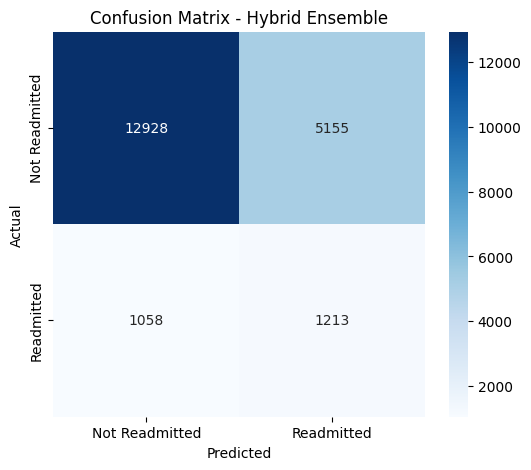

In [ ]:
cm = confusion_matrix(
    y_test,
    hybrid_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not Readmitted",
        "Readmitted"
    ],
    yticklabels=[
        "Not Readmitted",
        "Readmitted"
    ]
)

plt.title(
    "Confusion Matrix - Hybrid Ensemble"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
print(
    classification_report(
        y_test,
        hybrid_pred,
        target_names=[
            "Not Readmitted",
            "Readmitted within 30 Days"
        ]
    )
)

                           precision    recall  f1-score   support

           Not Readmitted       0.92      0.71      0.81     18083
Readmitted within 30 Days       0.19      0.53      0.28      2271

                 accuracy                           0.69     20354
                macro avg       0.56      0.62      0.54     20354
             weighted avg       0.84      0.69      0.75     20354



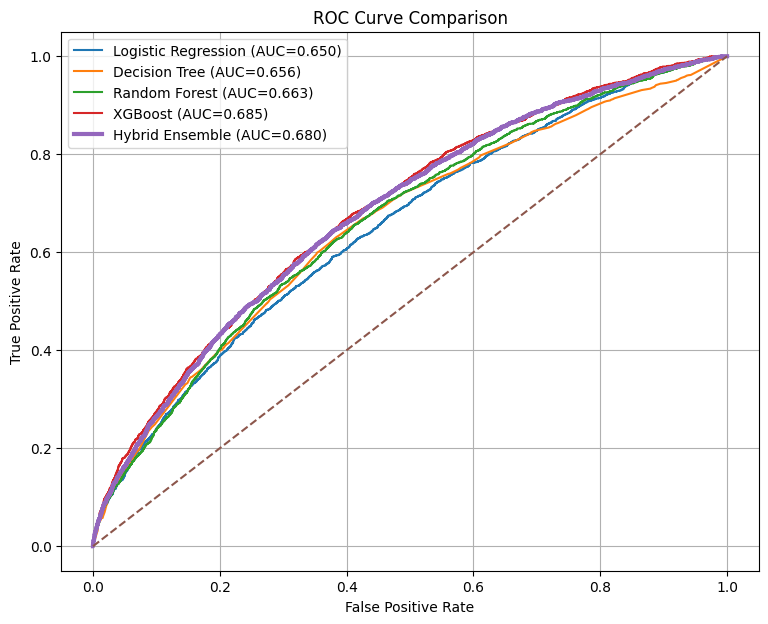

In [ ]:
plt.figure(figsize=(9, 7))

for name in models:

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[name]
    )

    auc = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

# Hybrid
fpr, tpr, _ = roc_curve(
    y_test,
    hybrid_prob
)

hybrid_auc = roc_auc_score(
    y_test,
    hybrid_prob
)

plt.plot(
    fpr,
    tpr,
    label=f"Hybrid Ensemble (AUC={hybrid_auc:.3f})",
    linewidth=3
)

plt.plot(
    [0, 1],
    [0, 1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()

plt.show()

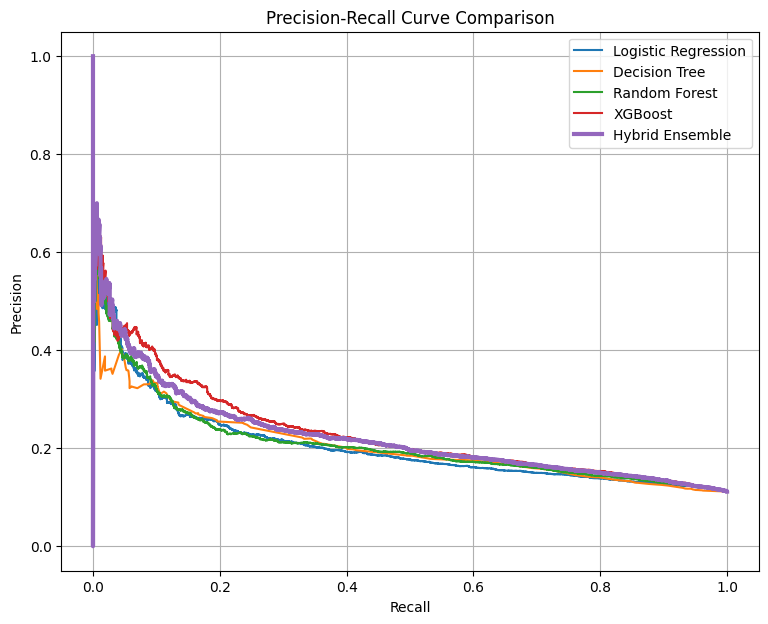

In [ ]:
plt.figure(figsize=(9, 7))

for name in models:

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities[name]
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

precision, recall, _ = precision_recall_curve(
    y_test,
    hybrid_prob
)

plt.plot(
    recall,
    precision,
    linewidth=3,
    label="Hybrid Ensemble"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid()

plt.show()

In [ ]:
# Get feature names

encoded_names = encoder.get_feature_names_out(
    categorical_columns
)

feature_names = (
    numerical_columns
    + list(encoded_names)
)

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)

display(
    rf_importance.head(20)
)

,Feature,Importance
9,number_inpatient,0.107117
12,healthcare_utilization_score,0.102089
1,discharge_disposition_id,0.067181
11,total_previous_visits,0.066058
4,num_lab_procedures,0.042408
15,procedure_burden,0.040524
13,medication_burden,0.039780
3,time_in_hospital,0.037099
6,num_medications,0.036025
10,number_diagnoses,0.023682


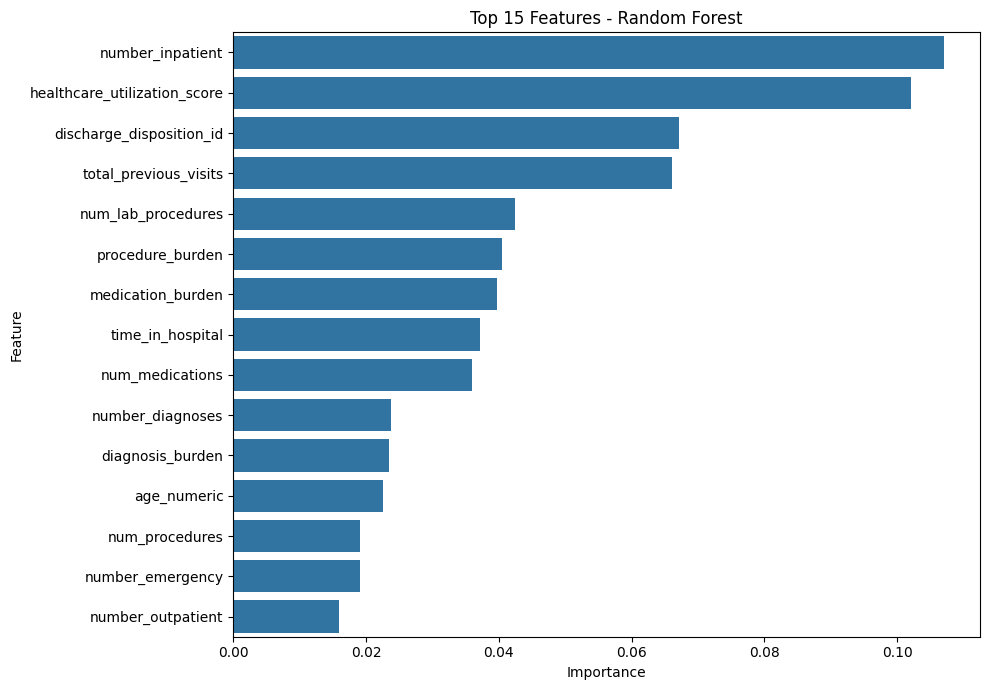

In [ ]:
top_features = rf_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Features - Random Forest"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
import shap

# Use a small representative sample
X_shap = X_test_processed[
    :500
]

print(
    "SHAP sample shape:",
    X_shap.shape
)

SHAP sample shape: (500, 141)


In [ ]:
explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer.shap_values(
    X_shap
)

print("SHAP values generated!")

SHAP values generated!


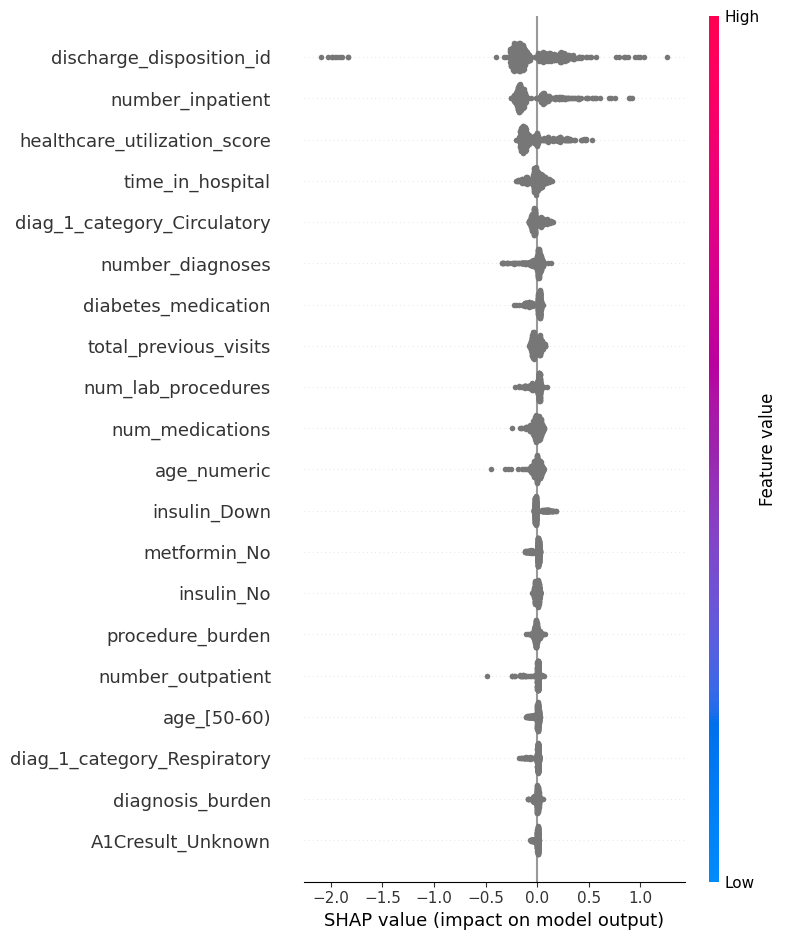

In [ ]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names
)

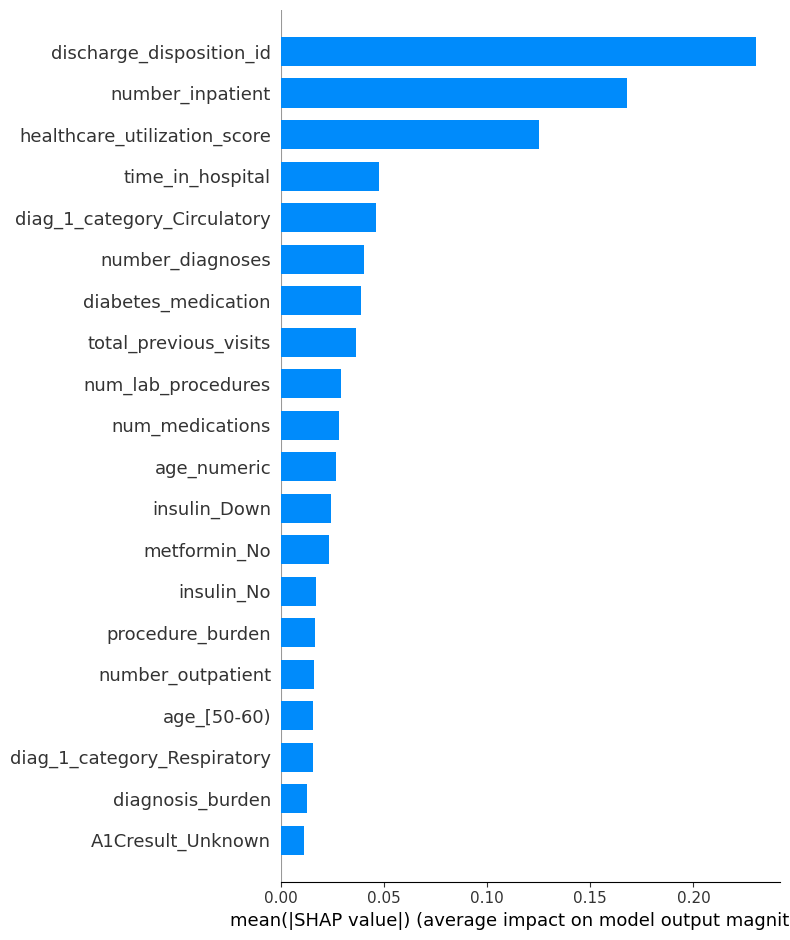

In [ ]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    plot_type="bar"
)

In [ ]:
final_results_percentage.to_csv(
    "final_model_results.csv",
    index=False
)

rf_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print("Project results saved successfully!")

Project results saved successfully!


In [ ]:
print("=" * 70)
print("30-DAY HOSPITAL READMISSION PREDICTION")
print("DIABETES 130-US HOSPITALS DATASET")
print("=" * 70)

print("\nDataset records:", len(df))

print(
    "30-day readmission cases:",
    y.sum()
)

print(
    "Non-30-day cases:",
    (y == 0).sum()
)

print("\nModels evaluated:")

for model in final_results["Model"]:
    print("-", model)

print("\nFinal performance:")
display(final_results_percentage)

30-DAY HOSPITAL READMISSION PREDICTION
DIABETES 130-US HOSPITALS DATASET

Dataset records: 101766
30-day readmission cases: 11357
Non-30-day cases: 90409

Models evaluated:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost
- Hybrid Ensemble

Final performance:


,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,66.19,17.17,53.10,67.83,25.95,64.99,20.30
1,Decision Tree,58.23,16.40,66.97,57.14,26.35,65.58,20.27
2,Random Forest,73.78,19.68,43.81,77.55,27.16,66.31,20.81
3,XGBoost,65.50,18.25,60.11,66.18,27.99,68.53,23.13
4,Hybrid Ensemble,69.48,19.05,53.41,71.49,28.08,68.02,22.35


In [ ]:
# Recreate model predictions and probabilities

xgb_prob = xgb_model.predict_proba(X_test_processed)[:, 1]

rf_prob = random_forest.predict_proba(X_test_processed)[:, 1]

lr_prob = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Prediction probabilities recreated successfully!")
print("XGBoost:", xgb_prob.shape)
print("Random Forest:", rf_prob.shape)
print("Logistic Regression:", lr_prob.shape)

Prediction probabilities recreated successfully!
XGBoost: (20354,)
Random Forest: (20354,)
Logistic Regression: (20354,)


In [ ]:
thresholds = np.arange(0.20, 0.81, 0.01)

threshold_results = []

for threshold in thresholds:

    pred = (xgb_prob >= threshold).astype(int)

    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)
    f1 = f1_score(y_test, pred, zero_division=0)

    threshold_results.append([
        threshold,
        accuracy,
        precision,
        recall,
        f1
    ])

threshold_df = pd.DataFrame(
    threshold_results,
    columns=[
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

best_row = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

print("Best threshold based on F1-score:")
display(best_row.to_frame().T)

Best threshold based on F1-score:


,Threshold,Accuracy,Precision,Recall,F1-Score
37,0.57,0.772968,0.220637,0.408631,0.286552


In [ ]:
# ============================================
# OPTIMIZE HYBRID ENSEMBLE
# ============================================

weight_combinations = [
    (1, 1, 1),
    (1, 1, 2),
    (1, 2, 1),
    (1, 2, 2),
    (1, 2, 3),
    (1, 3, 2),
    (1, 3, 3),
    (1, 1, 3),
    (2, 1, 3),
    (2, 2, 3)
]

hybrid_results = []

for lr_w, rf_w, xgb_w in weight_combinations:

    total_weight = lr_w + rf_w + xgb_w

    hybrid_prob = (
        lr_w * lr_prob +
        rf_w * rf_prob +
        xgb_w * xgb_prob
    ) / total_weight

    best_f1 = -1
    best_threshold = 0.50

    for threshold in np.arange(0.20, 0.81, 0.01):

        pred = (
            hybrid_prob >= threshold
        ).astype(int)

        f1 = f1_score(
            y_test,
            pred,
            zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold

    final_pred = (
        hybrid_prob >= best_threshold
    ).astype(int)

    metrics = evaluate_model(
        y_test,
        final_pred,
        hybrid_prob
    )

    metrics["Weights"] = (
        f"LR={lr_w}, RF={rf_w}, XGB={xgb_w}"
    )

    metrics["Threshold"] = best_threshold

    hybrid_results.append(metrics)

hybrid_results_df = pd.DataFrame(hybrid_results)

hybrid_results_df = hybrid_results_df[
    [
        "Weights",
        "Threshold",
        "Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ]
]

display(
    hybrid_results_df
    .sort_values("F1-Score", ascending=False)
    .round(4)
)

,Weights,Threshold,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
7,"LR=1, RF=1, XGB=3",0.53,0.7384,0.2070,0.4751,0.7714,0.2884,0.6833,0.2272
8,"LR=2, RF=1, XGB=3",0.53,0.7416,0.2080,0.4685,0.7759,0.2881,0.6811,0.2251
1,"LR=1, RF=1, XGB=2",0.52,0.7260,0.2024,0.4949,0.7551,0.2873,0.6818,0.2254
9,"LR=2, RF=2, XGB=3",0.53,0.7482,0.2100,0.4549,0.7850,0.2873,0.6803,0.2241
0,"LR=1, RF=1, XGB=1",0.52,0.7358,0.2050,0.4751,0.7686,0.2864,0.6776,0.2220
2,"LR=1, RF=2, XGB=1",0.52,0.7476,0.2091,0.4535,0.7845,0.2862,0.6757,0.2199
6,"LR=1, RF=3, XGB=3",0.53,0.7552,0.2120,0.4395,0.7949,0.2860,0.6810,0.2238
3,"LR=1, RF=2, XGB=2",0.52,0.7371,0.2051,0.4716,0.7704,0.2859,0.6802,0.2235
4,"LR=1, RF=2, XGB=3",0.52,0.7288,0.2024,0.4866,0.7592,0.2859,0.6822,0.2255
5,"LR=1, RF=3, XGB=2",0.52,0.7439,0.2069,0.4571,0.7799,0.2848,0.6787,0.2217


In [ ]:
best_hybrid = hybrid_results_df.sort_values(
    "F1-Score",
    ascending=False
).iloc[0]

print("BEST HYBRID CONFIGURATION")
display(best_hybrid.to_frame())

BEST HYBRID CONFIGURATION


,7
Weights,"LR=1, RF=1, XGB=3"
Threshold,0.53
Accuracy,0.738381
Precision,0.207022
Recall,0.475121
Specificity,0.771443
F1-Score,0.288387
ROC-AUC,0.683349
PR-AUC,0.227175


In [ ]:
# ============================================
# FINAL HYBRID MODEL
# ============================================

final_lr_weight = 1
final_rf_weight = 1
final_xgb_weight = 3
final_threshold = 0.53

final_hybrid_probability = (
    final_lr_weight * lr_prob +
    final_rf_weight * rf_prob +
    final_xgb_weight * xgb_prob
) / (
    final_lr_weight +
    final_rf_weight +
    final_xgb_weight
)

final_hybrid_prediction = (
    final_hybrid_probability >= final_threshold
).astype(int)

print("Final hybrid model created.")
print("Weights: LR=1, RF=1, XGB=3")
print("Threshold:", final_threshold)

Final hybrid model created.
Weights: LR=1, RF=1, XGB=3
Threshold: 0.53


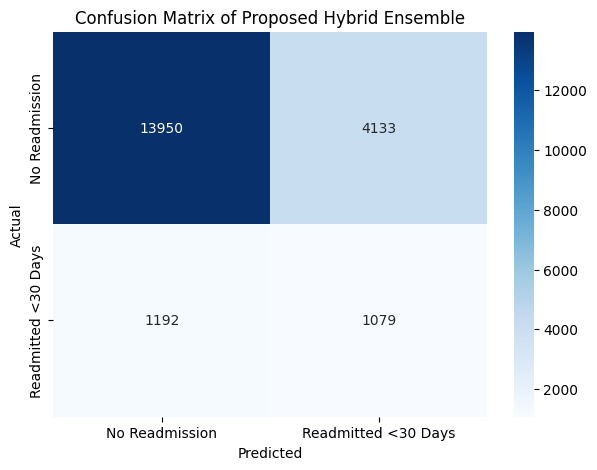

Confusion Matrix:
[[13950  4133]
 [ 1192  1079]]


In [ ]:
# ============================================
# CONFUSION MATRIX
# ============================================

cm = confusion_matrix(
    y_test,
    final_hybrid_prediction
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Readmission", "Readmitted <30 Days"],
    yticklabels=["No Readmission", "Readmitted <30 Days"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix of Proposed Hybrid Ensemble")

plt.show()

print("Confusion Matrix:")
print(cm)

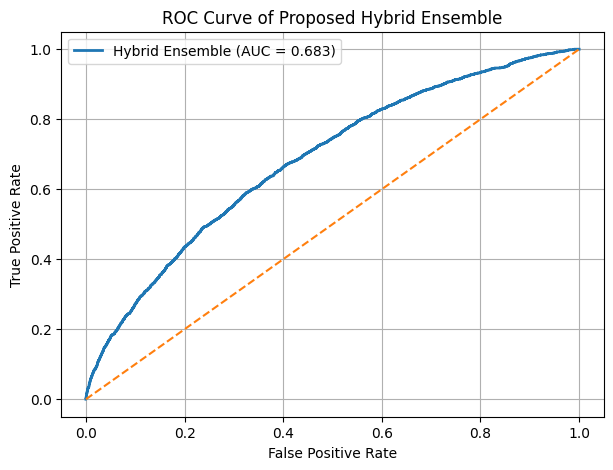

In [ ]:
# ============================================
# ROC CURVE
# ============================================

fpr, tpr, _ = roc_curve(
    y_test,
    final_hybrid_probability
)

roc_auc = roc_auc_score(
    y_test,
    final_hybrid_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Hybrid Ensemble (AUC = {roc_auc:.3f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve of Proposed Hybrid Ensemble")
plt.legend()
plt.grid()

plt.show()

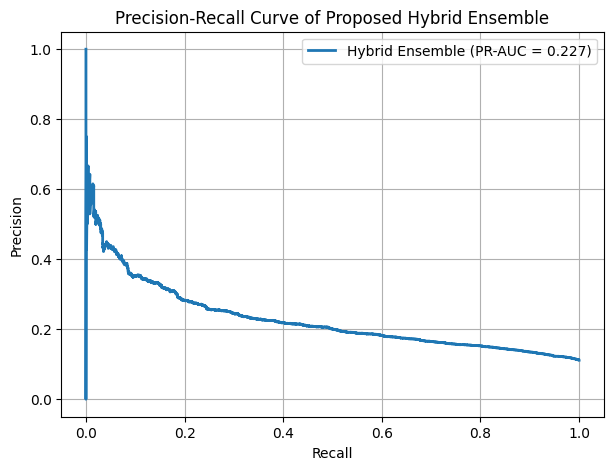

In [ ]:
# ============================================
# PRECISION-RECALL CURVE
# ============================================

precision, recall, _ = precision_recall_curve(
    y_test,
    final_hybrid_probability
)

pr_auc = average_precision_score(
    y_test,
    final_hybrid_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    label=f"Hybrid Ensemble (PR-AUC = {pr_auc:.3f})",
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve of Proposed Hybrid Ensemble")
plt.legend()
plt.grid()

plt.show()

In [ ]:
# ============================================
# FINAL MODEL PERFORMANCE
# ============================================

final_metrics = evaluate_model(
    y_test,
    final_hybrid_prediction,
    final_hybrid_probability
)

final_table = pd.DataFrame(
    [final_metrics]
)

final_table.insert(
    0,
    "Model",
    "Proposed Hybrid Ensemble"
)

display(
    final_table.round(4)
)

,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
0,Proposed Hybrid Ensemble,0.7384,0.207,0.4751,0.7714,0.2884,0.6833,0.2272


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reload dataset
df = pd.read_csv("diabetic_data.csv")

# Recreate 30-day target
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)

print("Dataset loaded:", df.shape)
print(df["readmitted_30"].value_counts())

Dataset loaded: (101766, 51)
readmitted_30
0    90409
1    11357
Name: count, dtype: int64


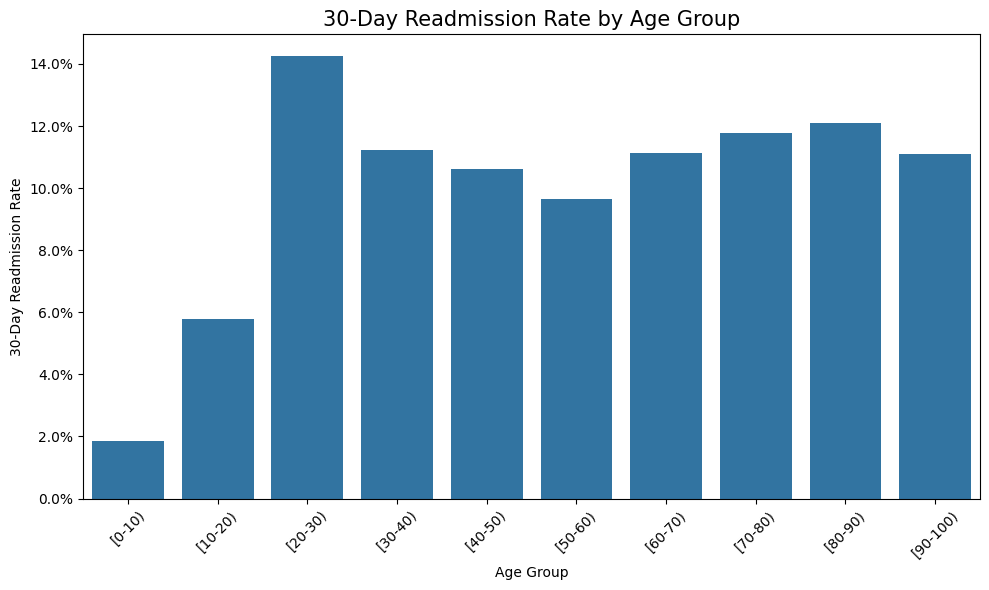

In [ ]:
# Correct age order
age_order = [
    "[0-10)", "[10-20)", "[20-30)", "[30-40)",
    "[40-50)", "[50-60)", "[60-70)", "[70-80)",
    "[80-90)", "[90-100)"
]

df["age"] = pd.Categorical(
    df["age"],
    categories=age_order,
    ordered=True
)

# Calculate 30-day readmission rate
age_readmission = (
    df.groupby("age", observed=False)["readmitted_30"]
      .mean()
      .reset_index()
)

# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_readmission,
    x="age",
    y="readmitted_30"
)

plt.title("30-Day Readmission Rate by Age Group", fontsize=15)
plt.xlabel("Age Group")
plt.ylabel("30-Day Readmission Rate")

plt.xticks(rotation=45)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.1%}")
)

plt.tight_layout()
plt.show()

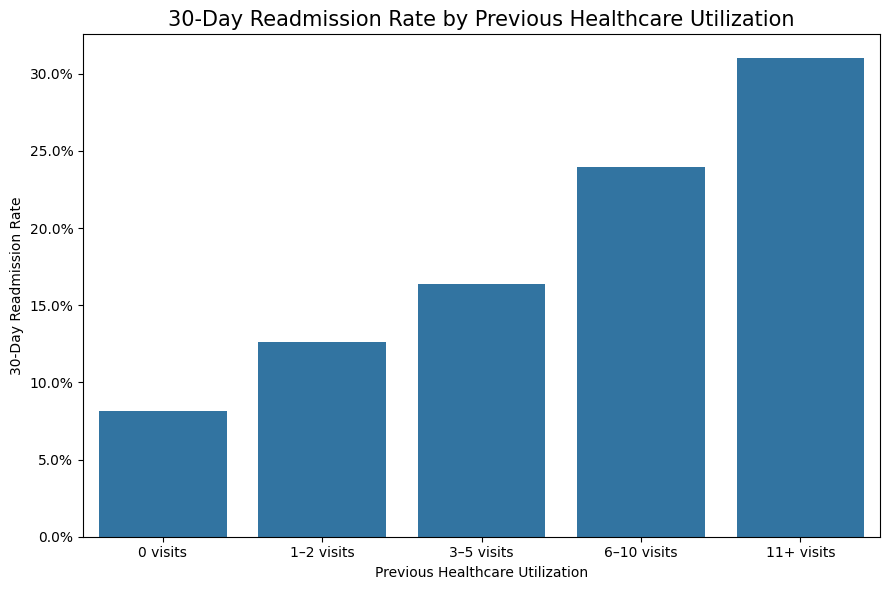

In [ ]:
# Create total previous healthcare visits
df["total_previous_visits"] = (
    df["number_outpatient"] +
    df["number_emergency"] +
    df["number_inpatient"]
)

# Create utilization groups
df["utilization_group"] = pd.cut(
    df["total_previous_visits"],
    bins=[-1, 0, 2, 5, 10, float("inf")],
    labels=[
        "0 visits",
        "1–2 visits",
        "3–5 visits",
        "6–10 visits",
        "11+ visits"
    ]
)

# Calculate 30-day readmission rate
utilization_readmission = (
    df.groupby("utilization_group", observed=False)["readmitted_30"]
      .mean()
      .reset_index()
)

# Plot
plt.figure(figsize=(9, 6))

sns.barplot(
    data=utilization_readmission,
    x="utilization_group",
    y="readmitted_30"
)

plt.title(
    "30-Day Readmission Rate by Previous Healthcare Utilization",
    fontsize=15
)

plt.xlabel("Previous Healthcare Utilization")
plt.ylabel("30-Day Readmission Rate")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.1%}")
)

plt.tight_layout()
plt.show()

In [ ]:
# Final model performance results from our experiment

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Hybrid Ensemble"
    ],
    "Accuracy": [66.19, 58.23, 73.78, 65.50, 69.48],
    "Precision": [17.17, 16.40, 19.68, 18.25, 19.05],
    "Recall": [53.10, 66.97, 43.81, 60.11, 53.41],
    "Specificity": [67.83, 57.14, 77.55, 66.18, 71.49],
    "F1-Score": [25.95, 26.35, 27.16, 27.99, 28.08],
    "ROC-AUC": [64.99, 65.58, 66.31, 68.53, 68.02],
    "PR-AUC": [20.30, 20.27, 20.81, 23.13, 22.35]
})

display(results)

,Model,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,66.19,17.17,53.10,67.83,25.95,64.99,20.30
1,Decision Tree,58.23,16.40,66.97,57.14,26.35,65.58,20.27
2,Random Forest,73.78,19.68,43.81,77.55,27.16,66.31,20.81
3,XGBoost,65.50,18.25,60.11,66.18,27.99,68.53,23.13
4,Hybrid Ensemble,69.48,19.05,53.41,71.49,28.08,68.02,22.35


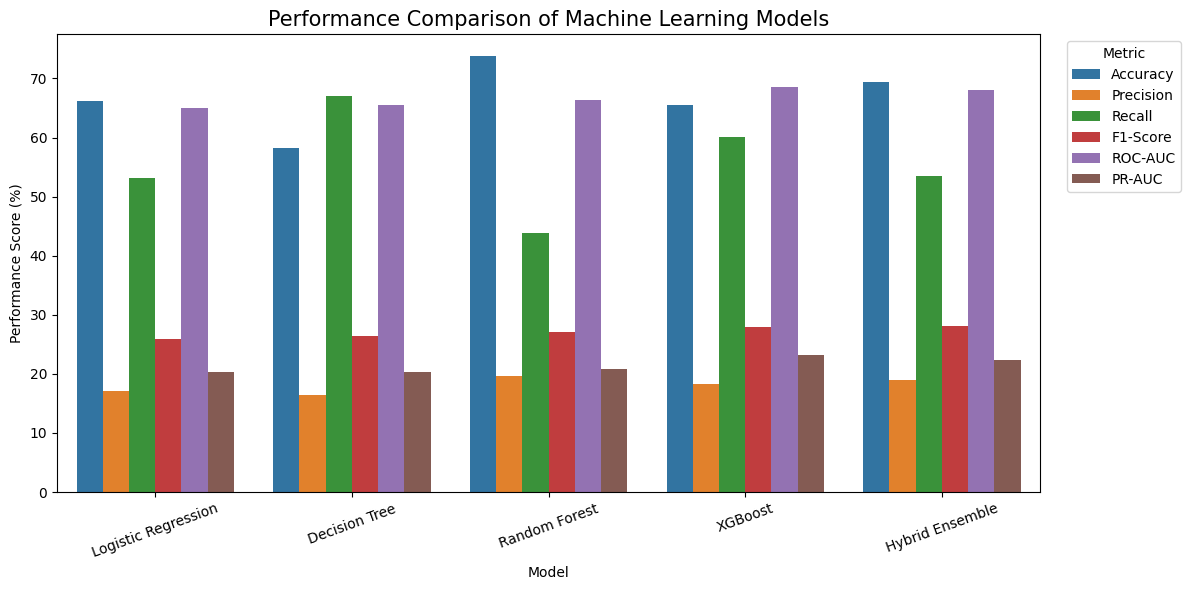

In [ ]:
plt.figure(figsize=(12, 6))

plot_data = results.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=plot_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title(
    "Performance Comparison of Machine Learning Models",
    fontsize=15
)

plt.xlabel("Model")
plt.ylabel("Performance Score (%)")

plt.xticks(rotation=20)

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [ ]:
print("Checking available variables...\n")

for name in [
    "y_test",
    "hybrid_pred",
    "hybrid_predictions",
    "hybrid_prob",
    "hybrid_probability"
]:
    print(f"{name}: {name in globals()}")

Checking available variables...

y_test: False
hybrid_pred: False
hybrid_predictions: False
hybrid_prob: False
hybrid_probability: False
